# WICOS: simple pre-processing
Each spectrogram is pre-processed in four steps:
1. **Noise removal:** clip every pixel below the sample's noise floor (sample median + a margin learned from pure-noise Doppler bins) to the floor.
2. **Doppler crop:** one fixed window around zero Doppler (bin 400) that keeps nearly all gesture energy (`ENERGY_KEPT`) in 99% of the training samples.
3. **Scaling:** map each sample so its noise floor becomes 0 and its maximum 1.
4. **Resize:** interpolate each sample to 128 × 128 (Doppler × time).

The steps are implemented in `src/preprocessing.py` (`remove_noise`, `preprocess`); this notebook learns and explains their two constants. The noise margin and the crop window are chosen on the **training samples only**. The other steps use only the sample itself, so they can be applied to all samples without leaking test information.

## Set-up

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../src").resolve()))
import preprocessing
from preprocessing import ZERO_DOPPLER, preprocess, remove_noise  # ZERO_DOPPLER = 400: centre of the 800 Doppler bins
from prepare_data import GESTURES, SEED, load_data, split

In [2]:
# Load all spectrograms (dB, Doppler bins x time bins) and the train/test split, as in prepare_data.py
spectrograms, metadata = load_data()
idx_train, idx_test, _ = split(metadata)
train_specs = [spectrograms[i] for i in idx_train]
labels_train = metadata.label.to_numpy()[idx_train]

# Example plots: the first training sample of each gesture (indices into train_specs)
GESTURE_EXAMPLES = [np.flatnonzero(labels_train == j)[0] for j in range(len(GESTURES))]
print(f"{len(spectrograms)} samples, {len(idx_train)} for training")

960 samples, 768 for training


## Noise removal
Most pixels of a spectrogram contain only noise: the gesture sits in a narrow band around zero Doppler (bin 400). The median of all pixels of a sample therefore lies in the noise, and we use it as that sample's **noise level**.

The noise spreads around this level, so half of the noise pixels lie above the median. To tell gesture from noise we need a **margin** above the median that pure noise almost never exceeds. We measure it on the Doppler bins far from zero Doppler (bins 0–99 and 700–799), which contain only noise:
1. For each training sample, subtract the sample median from its far-bin pixels.
2. Pool these differences of all training samples.
3. Take the 99.9th percentile as the margin: only 0.1% of the pure-noise pixels rise further above the median.

Only the training samples are used, so no test information leaks into the margin.

### Which Doppler bins contain only noise?
The margin is measured on "far" Doppler bins that we assume contain no gesture. To justify this without using the margin, we look at the level of each Doppler bin over all training samples:
- Each sample's level is first taken relative to its own median, so recordings with a different gain line up.
- **Median over time:** the typical level of a Doppler bin. Pure noise gives a flat line; a gesture gives a bump around zero Doppler (bin 400).
- **99th percentile over time:** a gesture can be short, so it may not move the median. The 99th percentile shows whether a bin *ever* gets loud.

The lines are the median over the samples, the bands the 5–95% spread between samples. If both lines are flat and equally high at the edges, and only rise well inside them, those edge bins contain only noise.

In [3]:
# Far Doppler bins: assumed to contain only noise
FAR_RANGES = [(0, 100), (700, 800)]
FAR_BINS = np.concatenate([np.arange(lo, hi) for lo, hi in FAR_RANGES])

# Check without the margin: level of every Doppler bin over all training samples, relative to each sample's median
EDGE_BINS = 50  # outermost bins on each side that set the reference "edge" level
RISE_DB = 1     # a bin "rises" when its level is this many dB above the edge level

levels = {
    "median over time": np.stack([np.median(x, axis=1) - np.median(x) for x in train_specs]),            # samples x bins
    "99th percentile over time": np.stack([np.percentile(x, 99, axis=1) - np.median(x) for x in train_specs]),
}
for name, level in levels.items():
    profile = np.median(level, axis=0)
    edge = np.median(np.r_[profile[:EDGE_BINS], profile[-EDGE_BINS:]])
    above = np.flatnonzero(profile > edge + RISE_DB)
    print(f"{name:>26}: edge level {edge:5.1f} dB, rises > {RISE_DB} dB between bins {above.min()} and {above.max()}")

          median over time: edge level  -1.0 dB, rises > 1 dB between bins 280 and 526
 99th percentile over time: edge level   6.4 dB, rises > 1 dB between bins 202 and 578


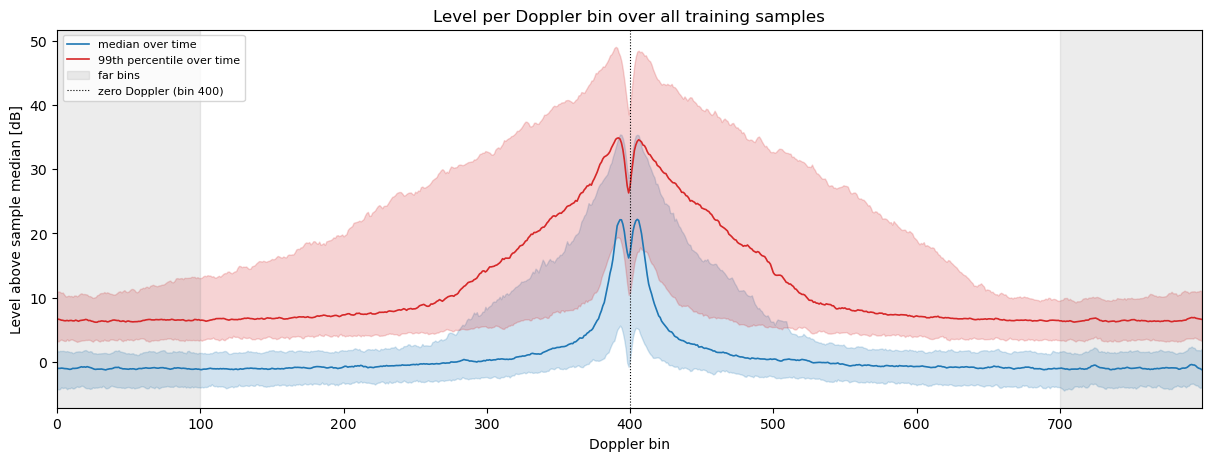

In [4]:
# Level per Doppler bin: median over the samples (line) and 5-95% spread between samples (band)
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
for (name, level), color in zip(levels.items(), ["C0", "C3"]):
    bins = np.arange(level.shape[1])
    ax.plot(bins, np.median(level, axis=0), color=color, linewidth=1.2, label=name)
    ax.fill_between(bins, *np.percentile(level, [5, 95], axis=0), color=color, alpha=0.2)

for k, (lo, hi) in enumerate(FAR_RANGES):
    ax.axvspan(lo, hi, color="gray", alpha=0.15, label="far bins" if k == 0 else None)
ax.axvline(ZERO_DOPPLER, color="black", linestyle=":", linewidth=0.8, label=f"zero Doppler (bin {ZERO_DOPPLER})")
ax.set_xlim(0, bins[-1])
ax.set_title("Level per Doppler bin over all training samples")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Level above sample median [dB]")
ax.legend(fontsize=8, loc="upper left")
plt.show()

In [5]:
# Noise margin from the data: how far pure noise rises above the sample median
NOISE_QUANTILE = 99  # percentile of pure noise that the threshold must exceed

# One margin for all samples: the percentile over the pooled far-bin noise of all training samples
far_noise = np.concatenate([(x[FAR_BINS] - np.median(x)).ravel() for x in train_specs])
margin_global = np.percentile(far_noise, NOISE_QUANTILE)
print(f"Noise margin ({NOISE_QUANTILE}th percentile of pooled noise above the median): {margin_global:.1f} dB")

Noise margin (99th percentile of pooled noise above the median): 7.9 dB


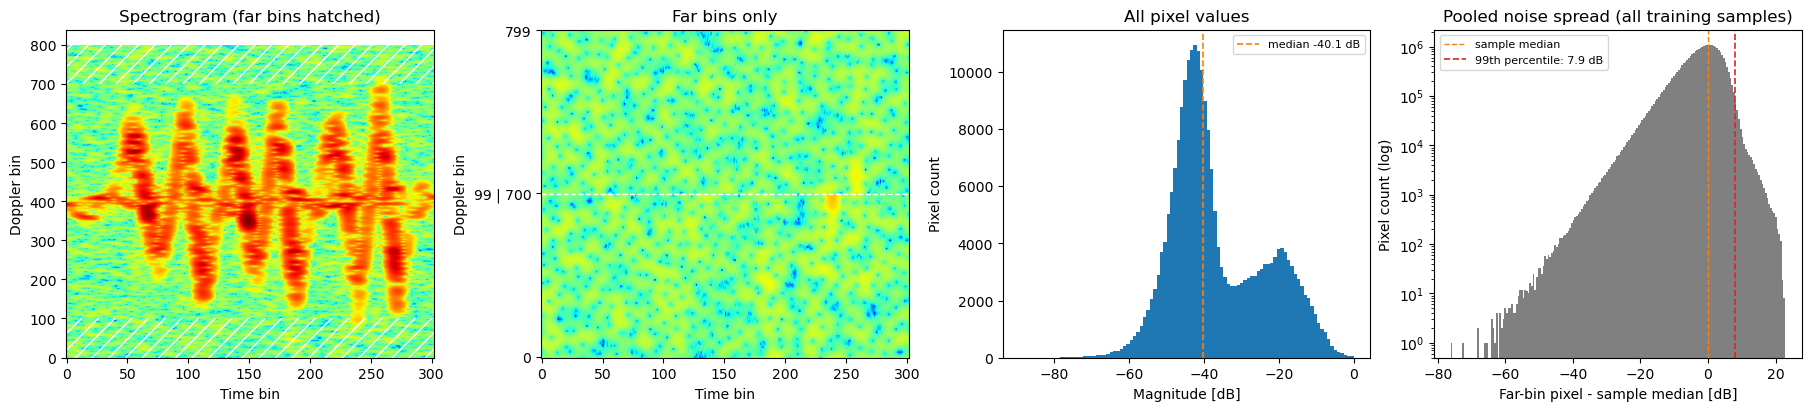

In [6]:
# Steps of the noise margin for one training sample, and the pooled noise of all training samples
x_ex = train_specs[2]
median_ex = np.median(x_ex)
far_ex = x_ex[FAR_BINS]  # far bins stacked: 200 x time bins

fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)

# 1. Full spectrogram, far bins marked
axes[0].imshow(x_ex, aspect="auto", origin="lower", cmap="jet")
for lo, hi in FAR_RANGES:
    axes[0].axhspan(lo, hi, facecolor="none", edgecolor="white", hatch="//", linewidth=0)
axes[0].set_title("Spectrogram (far bins hatched)")
axes[0].set_xlabel("Time bin")
axes[0].set_ylabel("Doppler bin")

# 2. Only the far bins, stacked; dashed line where the two ranges meet
n_low = FAR_RANGES[0][1] - FAR_RANGES[0][0]
axes[1].imshow(far_ex, aspect="auto", origin="lower", cmap="jet", vmin=x_ex.min(), vmax=x_ex.max())
axes[1].axhline(n_low - 0.5, color="white", linestyle="--", linewidth=1)
axes[1].set_yticks([0, n_low, len(FAR_BINS) - 1],
                   [FAR_BINS[0], f"{FAR_BINS[n_low - 1]} | {FAR_BINS[n_low]}", FAR_BINS[-1]])
axes[1].set_title("Far bins only")
axes[1].set_xlabel("Time bin")
axes[1].set_ylabel("Doppler bin")

# 3. All pixel values of the sample, with the median (noise level)
axes[2].hist(x_ex.ravel(), bins=100, color="C0")
axes[2].axvline(median_ex, color="C1", linestyle="--", linewidth=1.2, label=f"median {median_ex:.1f} dB")
axes[2].set_title("All pixel values")
axes[2].set_xlabel("Magnitude [dB]")
axes[2].set_ylabel("Pixel count")
axes[2].legend(fontsize=8)

# 4. Noise spread: far-bin pixels minus their sample median, pooled over all training samples
axes[3].hist(far_noise, bins=200, color="gray")
axes[3].axvline(0, color="C1", linestyle="--", linewidth=1, label="sample median")
axes[3].axvline(margin_global, color="C3", linestyle="--", linewidth=1.2,
                label=f"{NOISE_QUANTILE}th percentile: {margin_global:.1f} dB")
axes[3].set_yscale("log")  # log scale so the tail is visible
axes[3].set_title("Pooled noise spread (all training samples)")
axes[3].set_xlabel("Far-bin pixel - sample median [dB]")
axes[3].set_ylabel("Pixel count (log)")
axes[3].legend(fontsize=8)

plt.show()

**Noise removal strategy.** Per sample, the noise floor is the sample median plus the margin found above:

$$\text{floor} = \operatorname{median}(x) + \text{margin}$$

Pixels below the floor count as noise and are clipped to the floor. Pixels above it count as gesture. Only about 0.1% of the pure-noise pixels lie above the floor, so very little noise is mistaken for gesture. The median is taken per sample, so the floor follows each recording's own noise level. The margin is the same for all samples.

### Removing the noise
We apply the noise floor to every spectrogram. The noise-free spectrograms stay in dB; scaling to [0, 1] happens at the end, after the Doppler crop.

The plot after the next cell shows the steps for a few training samples (one row each):
1. **Spectrogram:** the raw sample in dB.
2. **Pixel values:** all pixels sorted from small to large. The dotted line is the sample median, the dashed line the noise floor (median + margin), and the grey area below it is the noise that will be removed.
3. **Noise removed:** every pixel below the floor is set to the floor, so only the gesture stands out (same dB colour scale as the raw spectrogram).

In [7]:
# remove_noise (src/preprocessing.py): clip every pixel below the noise floor (sample median + margin) to the floor
# Remove the noise from every spectrogram (same order as `spectrograms` and `metadata`)
spectrograms_clean, noise_floors = zip(*(remove_noise(x, margin_global) for x in spectrograms))
spectrograms_clean, noise_floors = list(spectrograms_clean), np.array(noise_floors)

removed = np.array([(x < f).mean() for x, f in zip(spectrograms, noise_floors)])
print(f"{len(spectrograms_clean)} spectrograms cleaned; noise floor {noise_floors.min():.1f} to {noise_floors.max():.1f} dB, "
      f"pixels removed per sample {removed.min():.1%} to {removed.max():.1%} (mean {removed.mean():.1%})")

960 spectrograms cleaned; noise floor -49.0 to -8.8 dB, pixels removed per sample 64.6% to 97.9% (mean 88.8%)


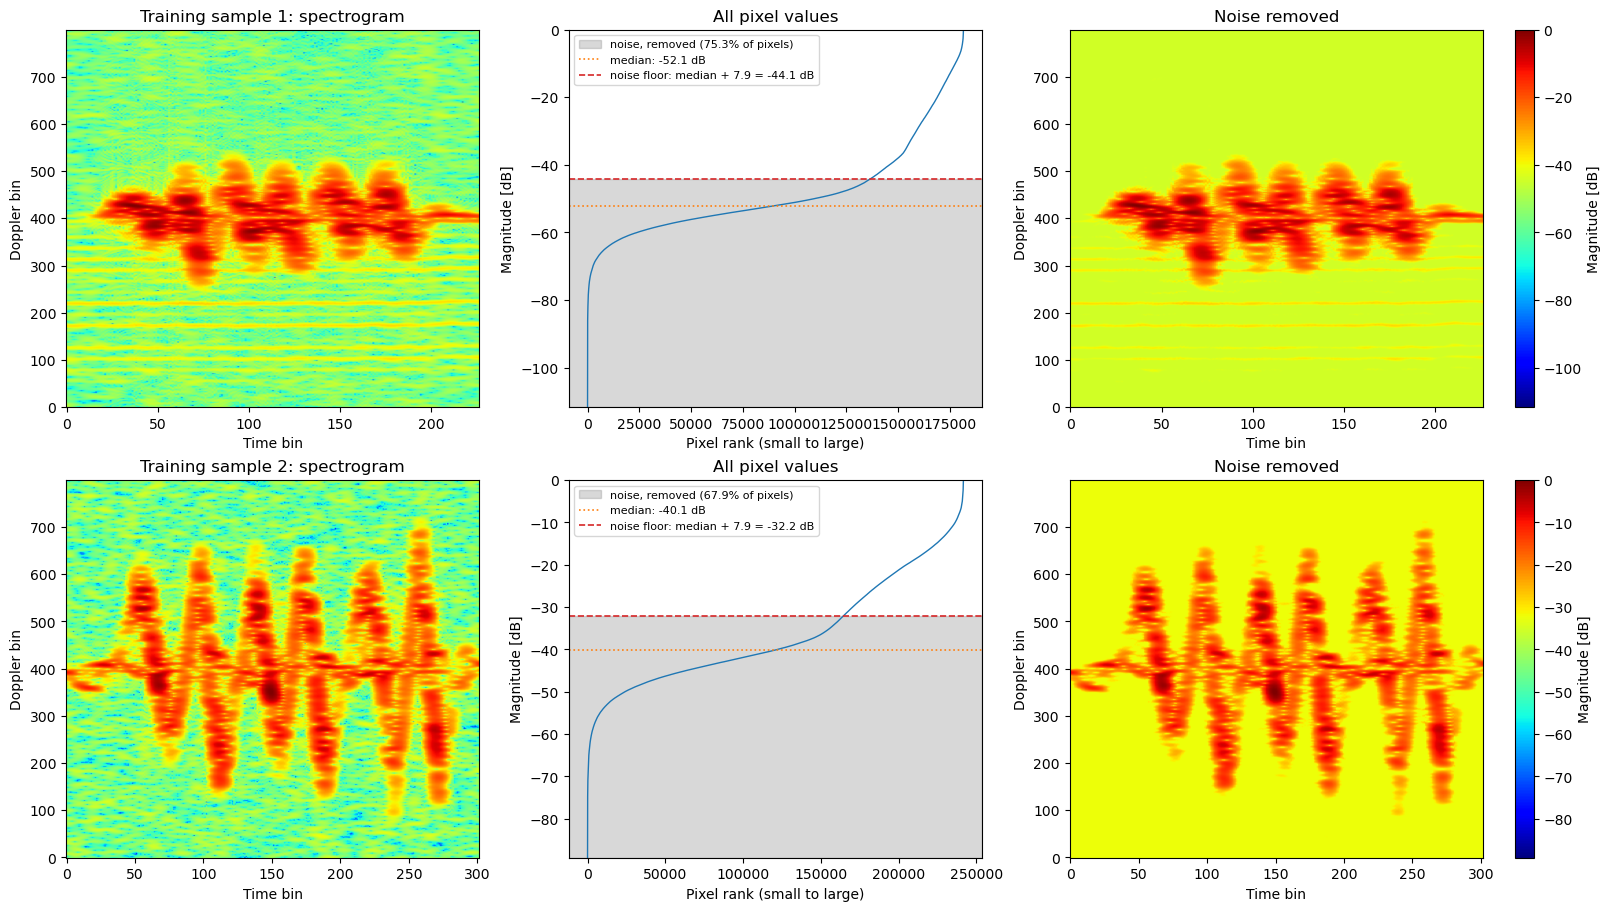

In [8]:
# Noise removal for a few example training samples, one row per sample
EXAMPLES = [1, 2]  # indices into train_specs

fig, axes = plt.subplots(len(EXAMPLES), 3, figsize=(16, 4.5 * len(EXAMPLES)), constrained_layout=True)

for row, i in zip(axes, EXAMPLES):
    x = train_specs[i]
    x_clean, floor = spectrograms_clean[idx_train[i]], noise_floors[idx_train[i]]
    median = np.median(x)
    pixels = np.sort(x.ravel())
    noise_share = (pixels < floor).mean()
    vmin, vmax = x.min(), x.max()  # same colour scale for the raw and noise-removed spectrograms

    # 1. Raw spectrogram
    row[0].imshow(x, aspect="auto", origin="lower", cmap="jet", vmin=vmin, vmax=vmax)
    row[0].set_title(f"Training sample {i}: spectrogram")
    row[0].set_xlabel("Time bin")
    row[0].set_ylabel("Doppler bin")

    # 2. All pixel values, sorted, with the median, the noise floor and the noise area below it
    row[1].plot(pixels, color="C0", linewidth=1)
    row[1].axhspan(vmin, floor, color="gray", alpha=0.3, label=f"noise, removed ({noise_share:.1%} of pixels)")
    row[1].axhline(median, color="C1", linestyle=":", linewidth=1.2, label=f"median: {median:.1f} dB")
    row[1].axhline(floor, color="C3", linestyle="--", linewidth=1.2,
                   label=f"noise floor: median + {margin_global:.1f} = {floor:.1f} dB")
    row[1].set_ylim(vmin, vmax)
    row[1].set_title("All pixel values")
    row[1].set_xlabel("Pixel rank (small to large)")
    row[1].set_ylabel("Magnitude [dB]")
    row[1].legend(fontsize=8, loc="upper left")

    # 3. Spectrogram with the noise floor applied (same dB scale as the raw spectrogram)
    im_db = row[2].imshow(x_clean, aspect="auto", origin="lower", cmap="jet", vmin=vmin, vmax=vmax)
    row[2].set_title("Noise removed")
    row[2].set_xlabel("Time bin")
    row[2].set_ylabel("Doppler bin")
    fig.colorbar(im_db, ax=row[2], label="Magnitude [dB]")

plt.show()

### Alternative: per-Doppler noise floor
The current floor is one value per sample. Noise is not equally strong in every Doppler bin, though, so a single floor removes too little noise in loud bins and too much gesture in quiet ones. An alternative estimates the noise **per Doppler bin**:
1. **Noise floor per Doppler bin:** the median over time of the linear power. A gesture is short, so most time bins of a Doppler bin hold only noise.
2. **Spectral subtraction:** subtract that floor from the linear power and clip negative values to 0.
3. **Dynamic range:** back to dB, and clip everything more than 40 dB below the sample maximum.
4. **Speckle removal:** a 3 x 3 median filter removes isolated noise pixels that survive the subtraction.

The cell below compares it with the current method on one training sample.

In [ ]:
# Alternative noise removal: per-Doppler noise floor with spectral subtraction, on one training sample
from scipy.signal import medfilt2d

DYNAMIC_RANGE = 40  # dB kept below the sample maximum

x = train_specs[2]                                 # dB, Doppler bins x time bins
S = 10 ** (x / 10)                                 # back to linear power
noise = np.median(S, axis=1, keepdims=True)        # per-Doppler noise floor: median over time
S_sub = np.clip(S - noise, 0, None)                # spectral subtraction

S_db = 10 * np.log10(S_sub + 1e-12)
S_db = np.maximum(S_db, S_db.max() - DYNAMIC_RANGE)  # 40 dB dynamic range
S_filt = medfilt2d(S_db, kernel_size=3)              # speckle removal

kept = (S_db > S_db.max() - DYNAMIC_RANGE).mean()
print(f"Pixels above the {DYNAMIC_RANGE} dB range: {kept:.1%} before, "
      f"{(S_filt > S_filt.max() - DYNAMIC_RANGE).mean():.1%} after the median filter "
      f"(current method keeps {(x >= noise_floors[idx_train[2]]).mean():.1%})")

fig, axes = plt.subplots(1, 5, figsize=(22, 4), constrained_layout=True)

# 1. Raw spectrogram
im = axes[0].imshow(x, aspect="auto", origin="lower", cmap="jet")
axes[0].set_title("Raw spectrogram")
axes[0].set_ylabel("Doppler bin")
fig.colorbar(im, ax=axes[0], label="dB")

# 2. Per-Doppler noise floor against the global floor of the current method
axes[1].plot(10 * np.log10(noise.ravel()), np.arange(len(noise)), color="C0", label="per-Doppler median")
axes[1].axvline(np.median(x), color="C1", linestyle=":", label="sample median (current)")
axes[1].axvline(noise_floors[idx_train[2]], color="C3", linestyle="--", label="median + margin (current)")
axes[1].set_ylim(0, len(noise) - 1)
axes[1].set_title("Noise floor per Doppler bin")
axes[1].set_xlabel("dB")
axes[1].legend(fontsize=8)

# 3. Current method: global floor, clip
im = axes[2].imshow(spectrograms_clean[idx_train[2]], aspect="auto", origin="lower", cmap="jet")
axes[2].set_title("Current: clip at median + margin")
fig.colorbar(im, ax=axes[2], label="dB")

# 4. Spectral subtraction, 40 dB range
im = axes[3].imshow(S_db, aspect="auto", origin="lower", cmap="jet")
axes[3].set_title(f"Spectral subtraction, {DYNAMIC_RANGE} dB range")
fig.colorbar(im, ax=axes[3], label="dB")

# 5. After the 3 x 3 median filter
im = axes[4].imshow(S_filt, aspect="auto", origin="lower", cmap="jet")
axes[4].set_title("+ 3 x 3 median filter")
fig.colorbar(im, ax=axes[4], label="dB")

for ax in axes[[0, 2, 3, 4]]:
    ax.set_xlabel("Time bin")
plt.show()

## Doppler crop

After noise removal, every pixel above the noise floor is gesture and every other pixel sits at the floor. In samples where the gesture stays close to zero Doppler, most Doppler bins are now empty; in samples where the gesture is spread over more bins, fewer are. The question is how many Doppler bins we can throw away.

- **Gesture energy per Doppler bin:** the linear power above the floor, $10^{x/10} - 10^{\text{floor}/10}$, summed over time. Pixels at the floor give 0, so only the gesture counts. We normalise it so it sums to 1 per sample.
- **Retained gesture energy:** for a symmetric window $[400 - w, 400 + w)$ around zero Doppler, the share of the gesture energy inside the window.
- **Half-width $w$ per sample:** the smallest $w$ that keeps at least `ENERGY_KEPT` of the gesture energy.

The crop is chosen from the training samples only.

In [9]:
ENERGY_KEPT = 0.99                    # share of the gesture energy the crop window must keep
HALF_WIDTHS = np.arange(ZERO_DOPPLER + 1)  # candidate half-widths w of the window [ZERO_DOPPLER - w, ZERO_DOPPLER + w)

def retained_energy(x_clean, floor):
    """Share of the gesture energy inside [ZERO_DOPPLER - w, ZERO_DOPPLER + w) for every half-width w."""
    power = 10 ** (x_clean / 10) - 10 ** (floor / 10)  # power above the floor: 0 for removed noise
    energy = power.sum(axis=1)                           # gesture energy per Doppler bin
    cum = np.r_[0, np.cumsum(energy / energy.sum())]     # normalised, cumulative over Doppler bins
    return cum[ZERO_DOPPLER + HALF_WIDTHS] - cum[ZERO_DOPPLER - HALF_WIDTHS]

def smallest_half_width(retained, kept=ENERGY_KEPT):
    """Smallest w whose window keeps at least `kept` of the gesture energy."""
    return int(np.argmax(retained >= kept))

In [10]:
# Retained gesture energy against w, and the smallest half-width w, for every training sample
retained_train = np.stack([retained_energy(spectrograms_clean[i], noise_floors[i]) for i in idx_train])  # samples x w
w_kept_train = np.array([smallest_half_width(r) for r in retained_train])
print(f"Half-width w over {len(w_kept_train)} training samples: median {np.median(w_kept_train):.0f}, "
      f"max {w_kept_train.max()}")

Half-width w over 768 training samples: median 95, max 398


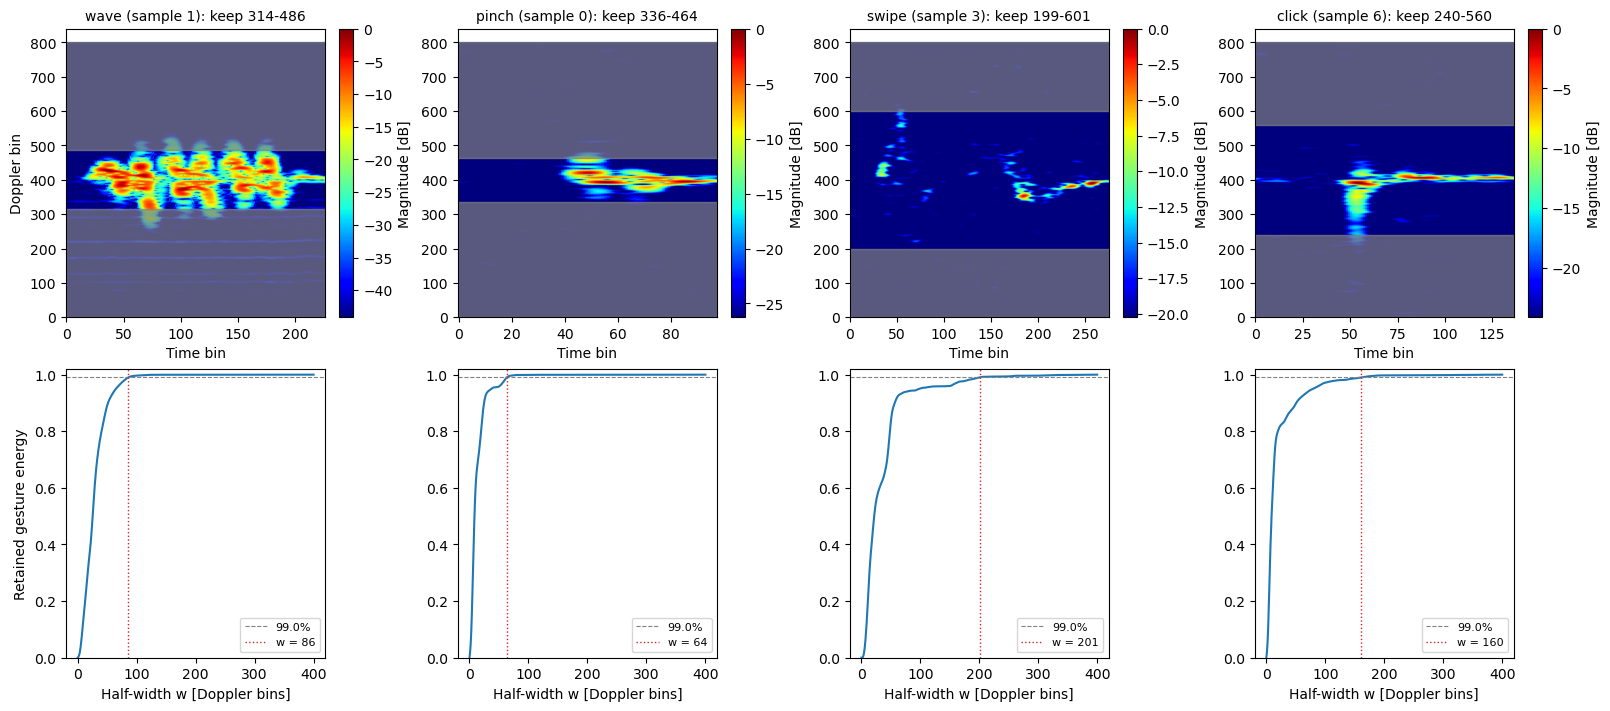

In [11]:
# One training sample per gesture, one column each:
# top: noise-free spectrogram with the bins outside the window greyed out, bottom: retained share against w
fig, axes = plt.subplots(2, len(GESTURE_EXAMPLES), figsize=(4 * len(GESTURE_EXAMPLES), 7), constrained_layout=True)

for col, i in zip(axes.T, GESTURE_EXAMPLES):
    x_clean = spectrograms_clean[idx_train[i]]
    w = w_kept_train[i]

    # 1. Full noise-free spectrogram (still in dB); grey = Doppler bins outside the window that could be removed
    im = col[0].imshow(x_clean, aspect="auto", origin="lower", cmap="jet")
    col[0].axhspan(0, ZERO_DOPPLER - w, color="gray", alpha=0.7)
    col[0].axhspan(ZERO_DOPPLER + w, x_clean.shape[0], color="gray", alpha=0.7)
    col[0].set_title(f"{GESTURES[labels_train[i]]} (sample {i}): keep {ZERO_DOPPLER - w}-{ZERO_DOPPLER + w}",
                     fontsize=10)
    col[0].set_xlabel("Time bin")
    fig.colorbar(im, ax=col[0], label="Magnitude [dB]")

    # 2. Retained share against w
    col[1].plot(HALF_WIDTHS, retained_train[i])
    col[1].axhline(ENERGY_KEPT, color="gray", linestyle="--", linewidth=0.8, label=f"{ENERGY_KEPT:.1%}")
    col[1].axvline(w, color="C3", linestyle=":", linewidth=1, label=f"w = {w}")
    col[1].set_ylim(0, 1.02)
    col[1].set_xlabel("Half-width w [Doppler bins]")
    col[1].legend(fontsize=8, loc="lower right")

axes[0, 0].set_ylabel("Doppler bin")
axes[1, 0].set_ylabel("Retained gesture energy")
plt.show()

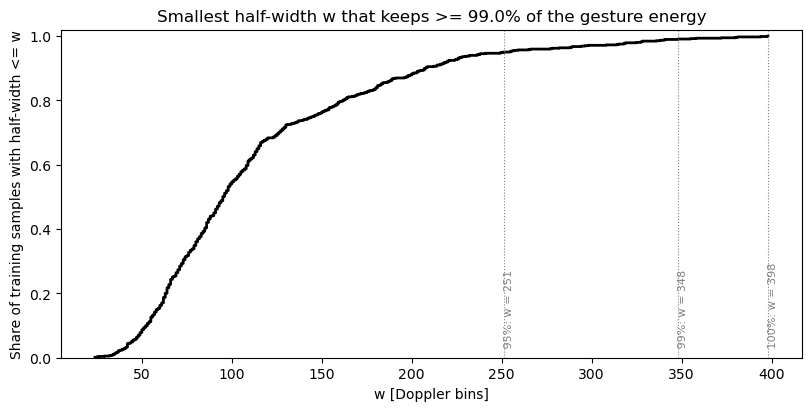

In [12]:
# Cumulative distribution: share of training samples whose w is at most a given value
def ecdf(values):
    v = np.sort(values)
    return v, np.arange(1, len(v) + 1) / len(v)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.step(*ecdf(w_kept_train), where="post", color="black", linewidth=2)

# w needed to cover 95%, 99% and 100% of the training samples
for q in [0.95, 0.99, 1.0]:
    w_q = np.quantile(w_kept_train, q, method="higher")
    ax.axvline(w_q, color="gray", linestyle=":", linewidth=0.8)
    ax.text(w_q, 0.02, f" {q:.0%}: w = {w_q}", rotation=90, va="bottom", fontsize=8, color="gray")

ax.set_title(f"Smallest half-width w that keeps >= {ENERGY_KEPT:.1%} of the gesture energy")
ax.set_xlabel("w [Doppler bins]")
ax.set_ylabel("Share of training samples with half-width <= w")
ax.set_ylim(0, 1.02)
plt.show()

## Fixed crop, scaling and resize
Every sample gets the **same** Doppler crop, so a Doppler row keeps the same velocity meaning in every sample:
- **Crop:** the half-width `w_crop` that keeps at least `ENERGY_KEPT` of the gesture energy in `CROP_COVERAGE` of the training samples, so the window is $[400 - w_{crop}, 400 + w_{crop})$.
- **Scaling:** $(x - \text{floor}) / (\max x - \text{floor})$ on the noise-free spectrogram, so the noise floor becomes 0 and the maximum 1.
- **Resize:** linear interpolation to 128 × 128. The Doppler axis is scaled by the same fixed factor for every sample; only the time axis is stretched per sample, because the recordings have different lengths.

In [13]:
CROP_COVERAGE = 0.99  # share of the training samples whose window must fit in the crop

# One fixed crop for all samples, from the training half-widths
w_crop = int(np.quantile(w_kept_train, CROP_COVERAGE, method="higher"))
DOPPLER_CROP = (ZERO_DOPPLER - w_crop, ZERO_DOPPLER + w_crop)
print(f"Doppler crop: bins {DOPPLER_CROP[0]}-{DOPPLER_CROP[1]} ({2 * w_crop} bins, w = {w_crop})")

# Pre-process every sample with the learned margin and crop (resize to 128 x 128, see src/preprocessing.py)
X_img = np.stack([preprocess(x, margin_global, DOPPLER_CROP) for x in spectrograms])
print(f"X_img: {X_img.shape}, values from {X_img.min():.2f} to {X_img.max():.2f}")

Doppler crop: bins 52-748 (696 bins, w = 348)


X_img: (960, 128, 128), values from 0.00 to 1.00


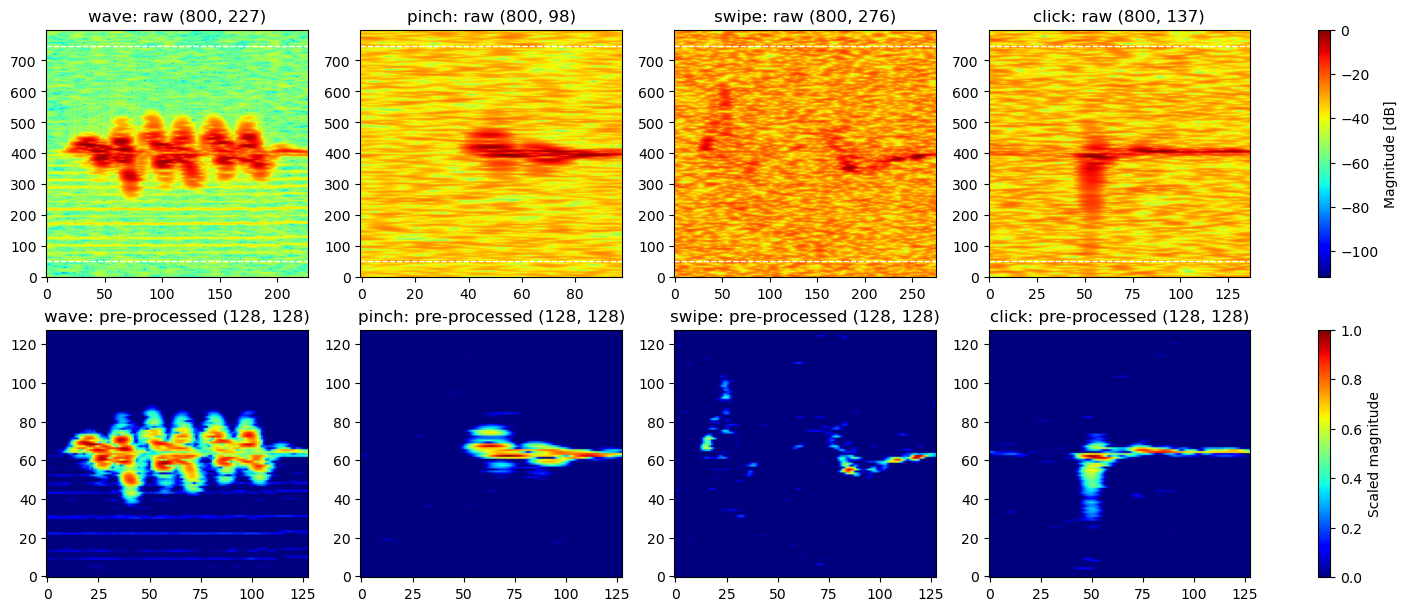

In [14]:
# Before / after pre-processing: one training sample per gesture
raw = [spectrograms[idx_train[i]] for i in GESTURE_EXAMPLES]
vmin, vmax = min(x.min() for x in raw), max(x.max() for x in raw)  # one dB scale for the shared colour bar

fig, axes = plt.subplots(2, len(GESTURE_EXAMPLES), figsize=(14, 6), constrained_layout=True)
for j, (i, x) in enumerate(zip(GESTURE_EXAMPLES, raw)):
    g = GESTURES[labels_train[i]]
    im_raw = axes[0, j].imshow(x, aspect="auto", origin="lower", cmap="jet", vmin=vmin, vmax=vmax)
    for b in DOPPLER_CROP:
        axes[0, j].axhline(b, color="white", linestyle="--", linewidth=1)
    axes[0, j].set_title(f"{g}: raw {x.shape}")
    im_pre = axes[1, j].imshow(X_img[idx_train[i]], aspect="auto", origin="lower", cmap="jet", vmin=0, vmax=1)
    axes[1, j].set_title(f"{g}: pre-processed {X_img[idx_train[i]].shape}")
fig.colorbar(im_raw, ax=axes[0], label="Magnitude [dB]")
fig.colorbar(im_pre, ax=axes[1], label="Scaled magnitude")
plt.show()

## The pre-processing function
`preprocess` in `src/preprocessing.py` takes one raw spectrogram (dB, Doppler bins × time bins) and runs all steps: noise removal, fixed Doppler crop, scaling and resize. The two parameters learned above from the training samples are stored there as the constants `NOISE_MARGIN` and `DOPPLER_CROP`, and `prepare_data.py` uses them to build the dataset. Only the sample itself is used otherwise, so it can be applied to any new sample without leaking test information.

The check below confirms that the stored constants match the values learned in this notebook. If the analysis above changes, update the constants in `src/preprocessing.py` and re-run `prepare_data.py`.

In [15]:
print(f"Learned here:          margin {margin_global:.2f} dB, Doppler crop {DOPPLER_CROP}")
print(f"src/preprocessing.py:  margin {preprocessing.NOISE_MARGIN:.2f} dB, Doppler crop {preprocessing.DOPPLER_CROP}")
assert abs(margin_global - preprocessing.NOISE_MARGIN) < 0.05 and DOPPLER_CROP == preprocessing.DOPPLER_CROP,     "the constants in src/preprocessing.py differ from the learned values: update them"

Learned here:          margin 7.93 dB, Doppler crop (52, 748)
src/preprocessing.py:  margin 7.90 dB, Doppler crop (52, 748)


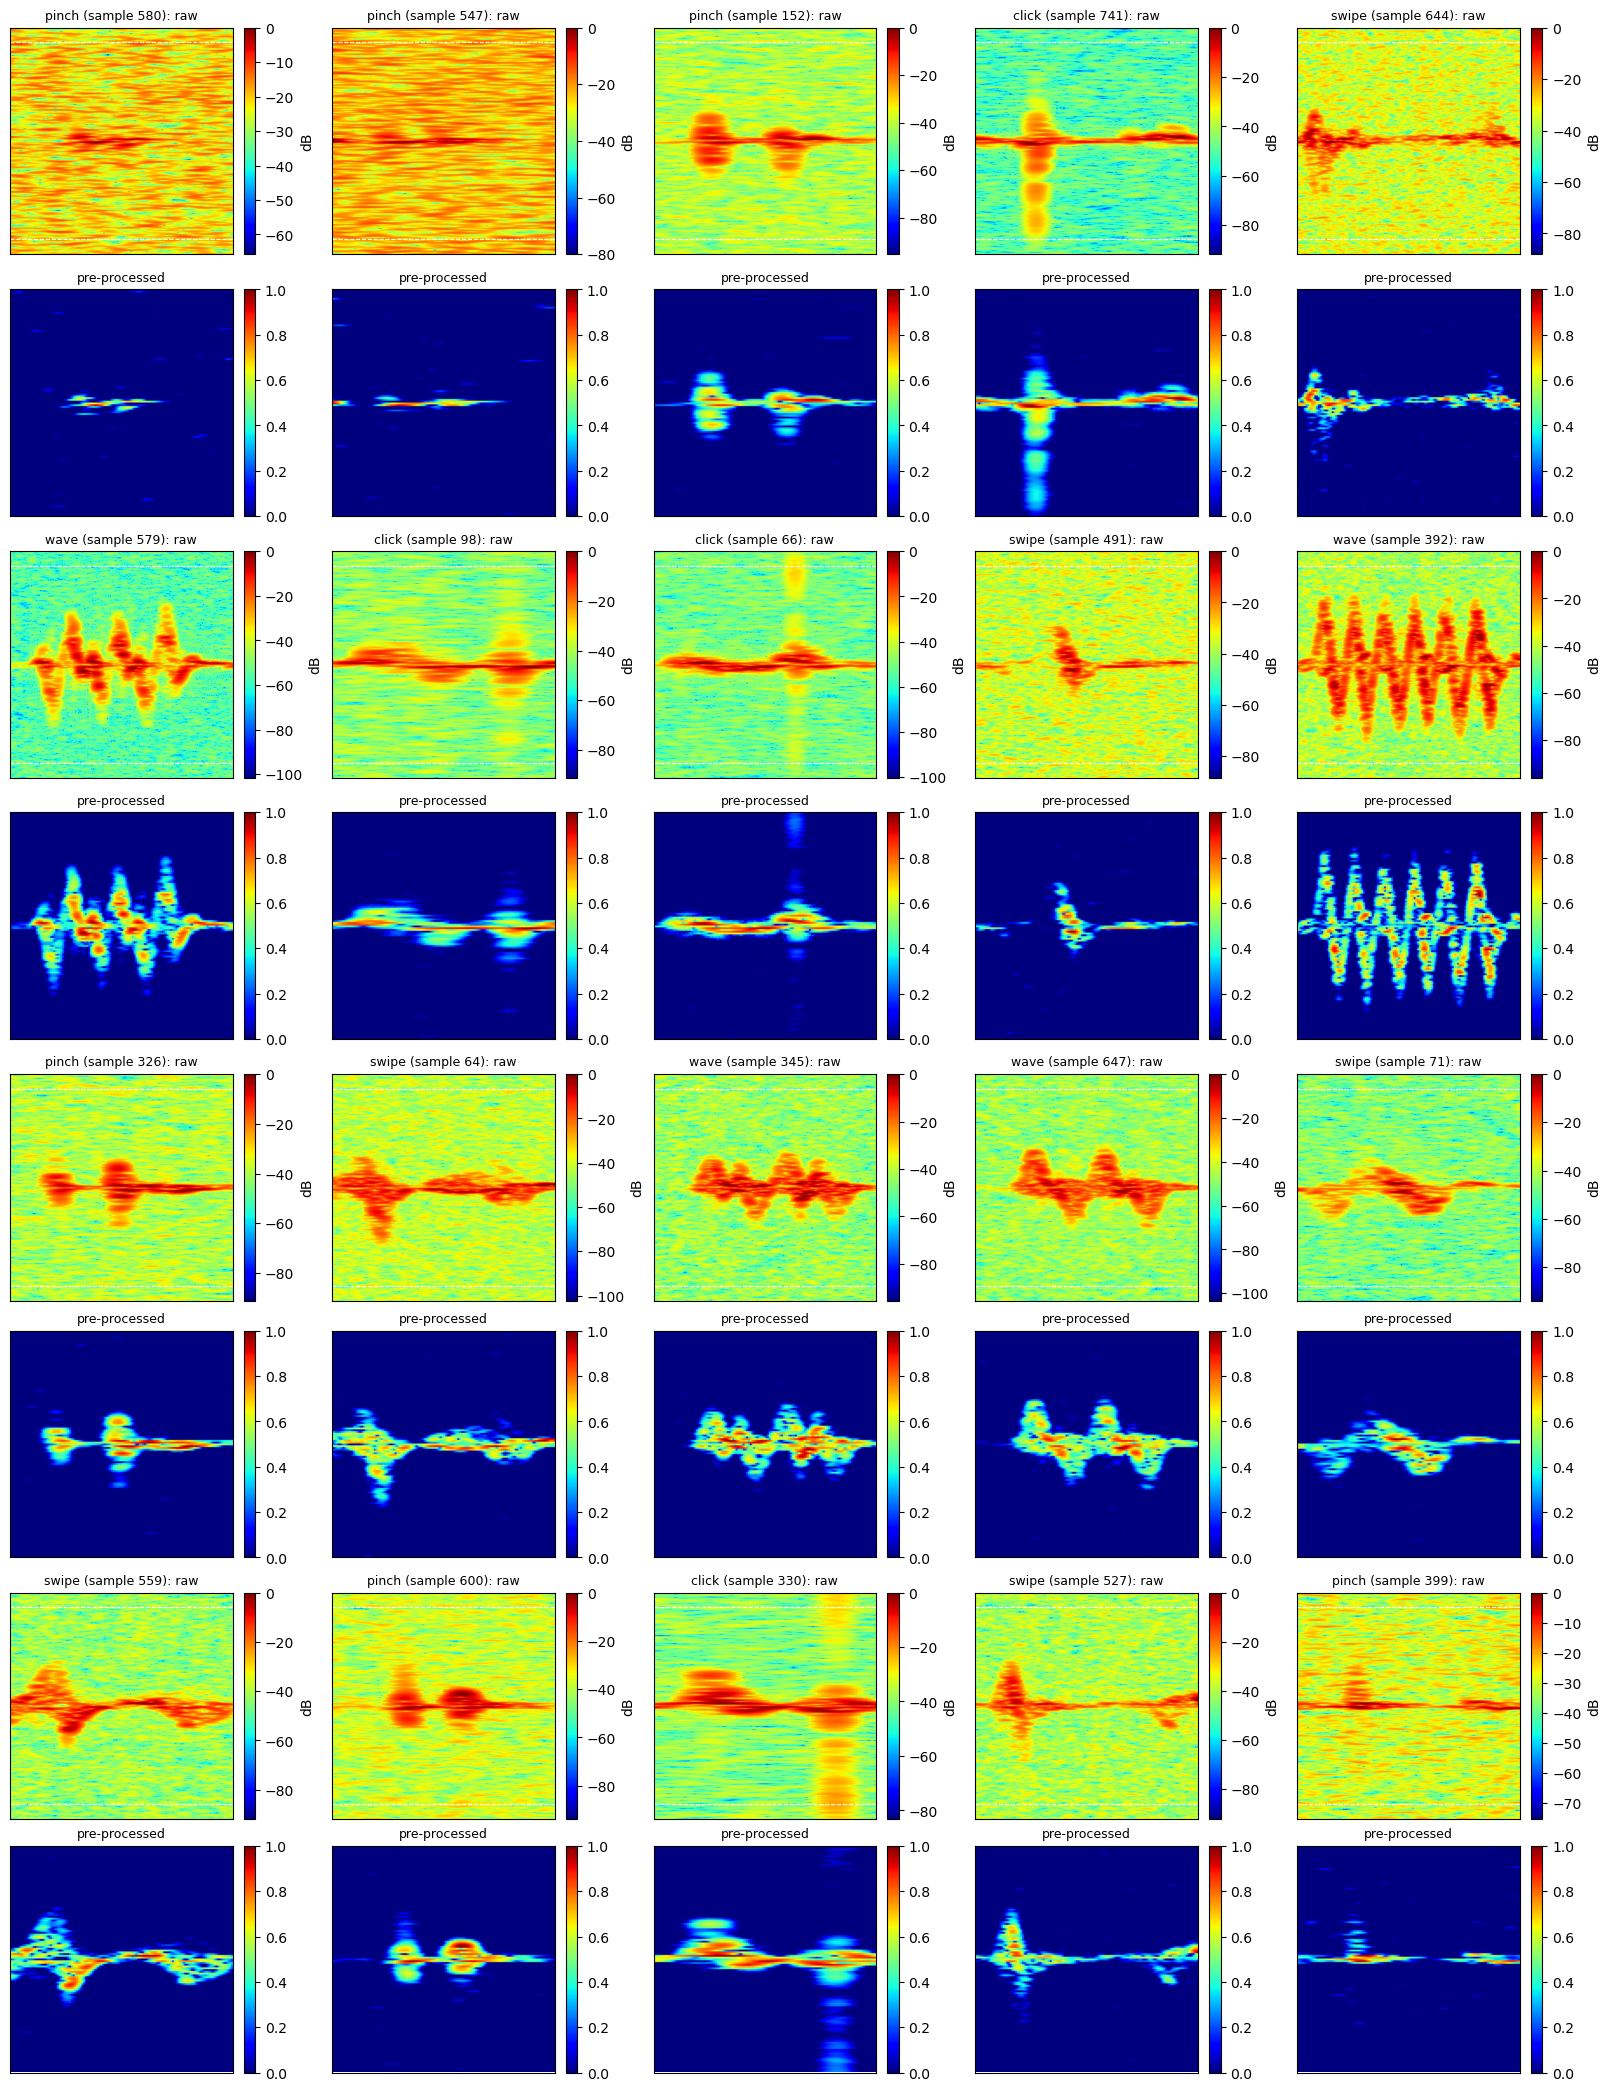

In [16]:
# 20 random training samples: raw spectrogram (crop marked) with its pre-processed image directly below it
N_RANDOM, N_COLS = 20, 5
rng = np.random.default_rng(SEED)
random_examples = rng.choice(len(train_specs), N_RANDOM, replace=False)  # indices into train_specs

n_rows = 2 * int(np.ceil(N_RANDOM / N_COLS))  # a raw row and a pre-processed row per group of N_COLS samples
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.2 * N_COLS, 2.6 * n_rows), constrained_layout=True)

for k, i in enumerate(random_examples):
    ax_raw, ax_pre = axes[2 * (k // N_COLS), k % N_COLS], axes[2 * (k // N_COLS) + 1, k % N_COLS]
    x = train_specs[i]

    im_raw = ax_raw.imshow(x, aspect="auto", origin="lower", cmap="jet")
    for b in DOPPLER_CROP:
        ax_raw.axhline(b, color="white", linestyle="--", linewidth=0.8)
    ax_raw.set_title(f"{GESTURES[labels_train[i]]} (sample {i}): raw", fontsize=9)
    fig.colorbar(im_raw, ax=ax_raw, label="dB")

    im_pre = ax_pre.imshow(preprocess(x), aspect="auto", origin="lower", cmap="jet", vmin=0, vmax=1)
    ax_pre.set_title("pre-processed", fontsize=9)
    fig.colorbar(im_pre, ax=ax_pre)

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()